# Does preprocessing improve our models?

We compared normalization, complete-pulse shape features, and an alternative bandpass filter. Every condition uses the same rows, pressure labels, grouped folds and fixed RF/boosting settings. No test waveforms were processed.

Training out-of-fold errors help compare candidates. Validation is exploratory because it has been inspected before. [Full explanation](PREPROCESSING_COMPARISON_RESULTS.md).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
RUN=Path('outputs/preprocessing_ablation_oct28')
metrics=pd.read_csv(RUN/'metrics.csv')
validation=metrics[metrics.split.eq('validation')]
display(validation.pivot(index=['variant','model'],columns='target',values=['mae_mmHg','rmse_mmHg']).round(2))

mae_mmHg        rmse_mmHg       
target                                  dbp    sbp       dbp    sbp
variant                   model                                    
Bandpass pulse shape      Boosting     8.95  16.77     12.39  21.86
                          RF           8.93  17.09     12.42  22.19
Constant                  mean        10.03  18.70     13.26  23.43
                          median      10.21  18.93     13.92  23.83
NK pulse shape            Boosting     8.85  16.69     12.28  21.87
                          RF           8.94  17.13     12.33  22.29
Normalized 37             Boosting     8.76  16.67     12.07  21.99
                          RF           8.75  16.75     12.16  22.16
Original + NK pulse shape Boosting     8.91  16.65     12.39  22.01
                          RF           8.81  16.54     12.17  22.08
Original 37               Boosting     8.89  17.12     12.24  22.53
                          RF           8.83  16.86     12.16  22.44

## What the changes did

Normalizing the current features gives small gains in window MAE. Adding complete-pulse features helps RF systolic error, but does little for diastolic error. Pulse features alone do not consistently beat the original features. Switching filters gives mixed results.

These improvements are modest. They do not establish why another team got a different score, because the teams also use different training sizes, labels, inclusion rules and held-out recordings.

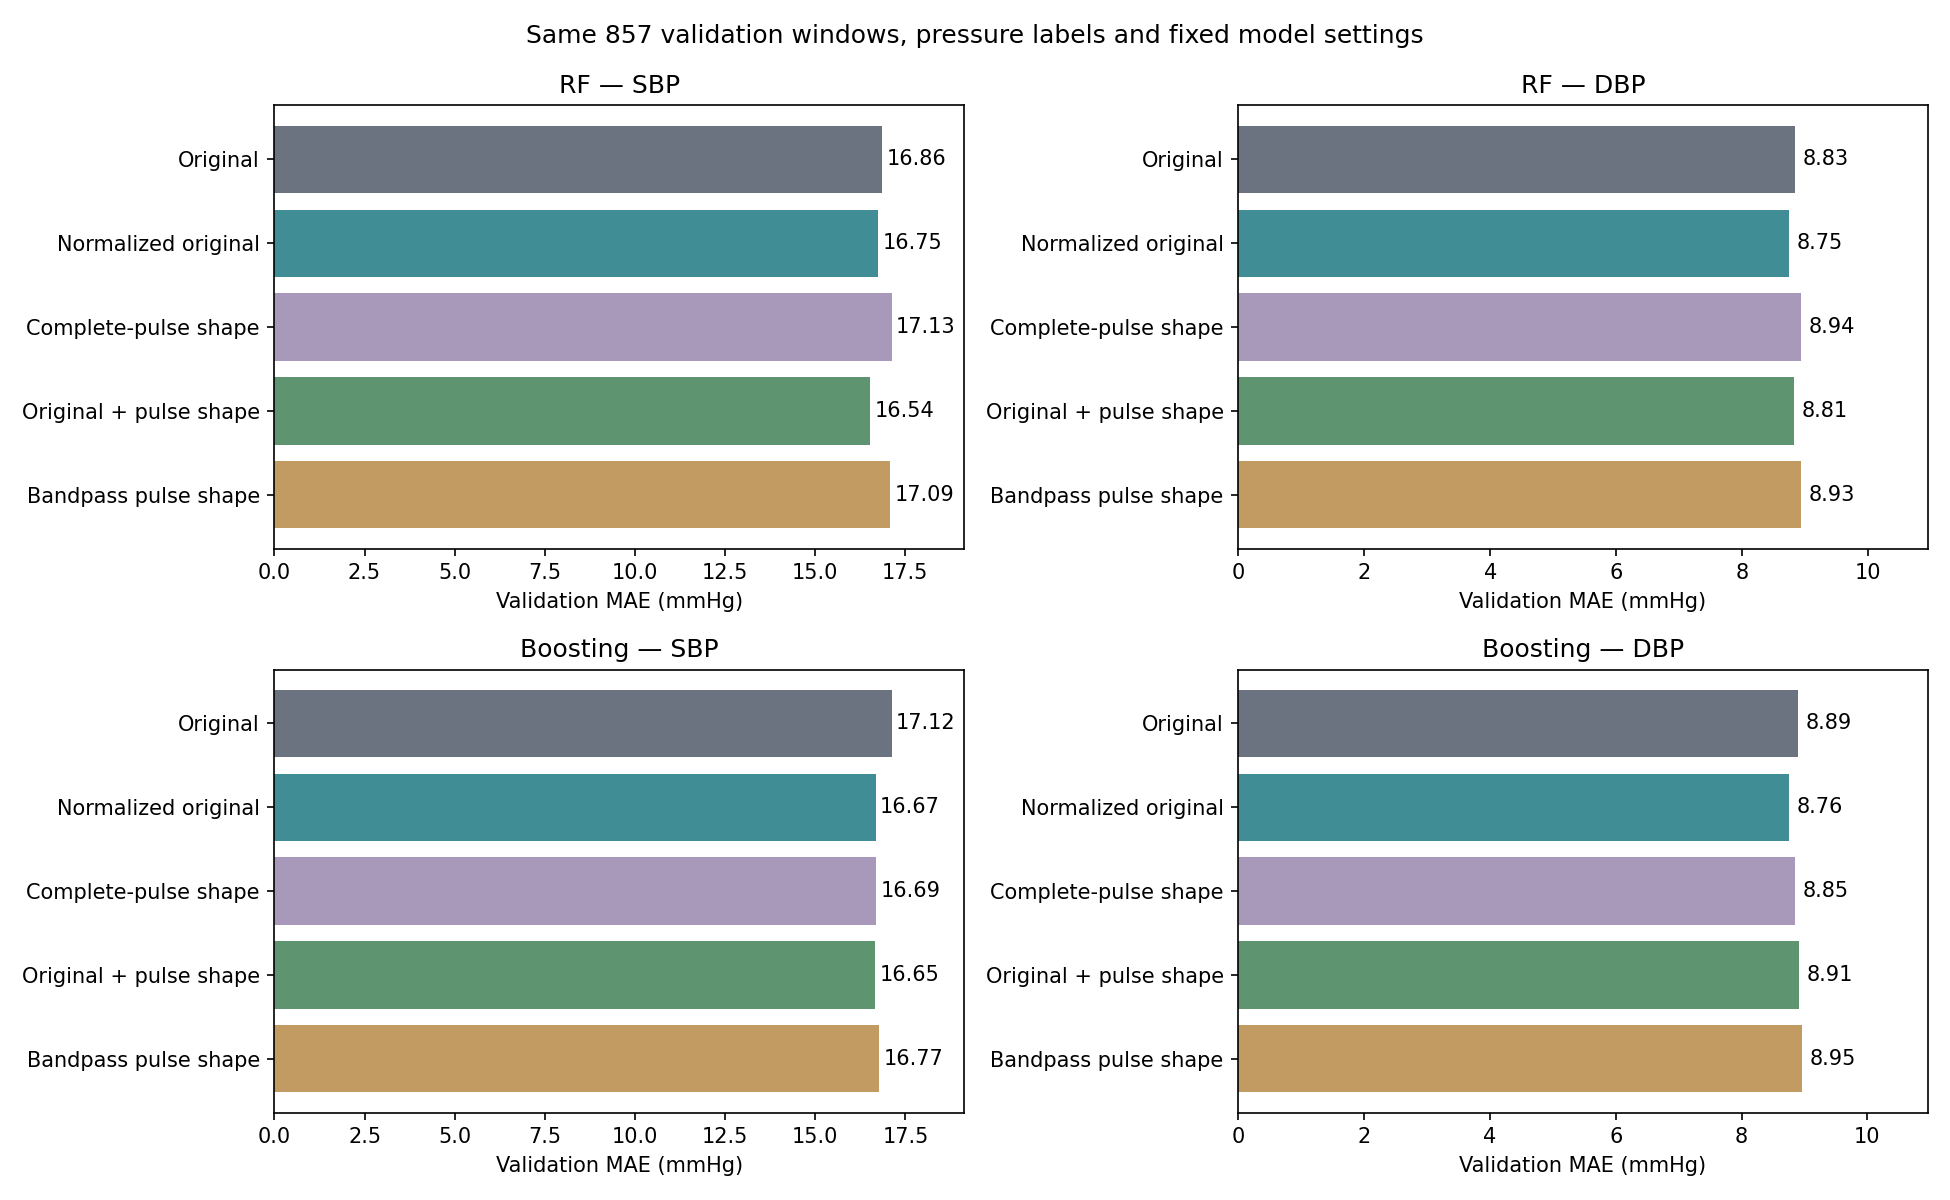

In [2]:
display(Image(filename=str(RUN/'validation_comparison.png')))

## Check each recording group equally

Window errors give more weight to recordings with more retained windows. Group-average errors give each detected overlap group equal weight. A gain in one view can disappear in the other. Positive values below mean lower equal-group MAE than the original features for the same model. Intervals are descriptive and do not account for all repeated development decisions.

In [3]:
gains=pd.read_csv(RUN/'paired_group_gains.csv')
display(gains[gains.split.eq('validation')].round(3))

,split,model,variant,target,gain_mmHg,ci_low,ci_high
20,validation,RF,Original 37,sbp,0.000,0.000,0.000
21,validation,RF,NK pulse shape,sbp,-0.275,-1.331,0.799
22,validation,RF,Original + NK pulse shape,sbp,0.413,0.061,0.782
23,validation,RF,Bandpass pulse shape,sbp,-0.202,-1.185,0.762
24,validation,RF,Normalized 37,sbp,-0.183,-1.043,0.644
25,validation,RF,Original 37,dbp,0.000,0.000,0.000
26,validation,RF,NK pulse shape,dbp,-0.268,-0.746,0.224
27,validation,RF,Original + NK pulse shape,dbp,-0.068,-0.268,0.121
28,validation,RF,Bandpass pulse shape,dbp,-0.230,-0.699,0.246
29,validation,RF,Normalized 37,dbp,0.040,-0.430,0.493


## Compare using training folds

This ranking averages the two targets' group-average out-of-fold MAE. It favors normalized features with boosting, but the difference is small. Selecting a condition from the ranking makes its reported score optimistic; it is not a new final test.

In [4]:
display(pd.read_json(RUN/'training_ranking.json').round(3))
audit=pd.read_csv(RUN/'pulse_audit.csv')
display(audit.groupby('split')[['nk_complete_pulses','bandpass_complete_pulses']].agg(['min','median']))

,variant,model,mean_target_group_mae
0,Normalized 37,Boosting,11.789
1,Original + NK pulse shape,RF,11.816
2,Original 37,RF,11.855
3,Normalized 37,RF,11.866
4,Bandpass pulse shape,RF,11.884
5,Original + NK pulse shape,Boosting,11.907
6,Original 37,Boosting,11.929
7,NK pulse shape,RF,11.930
8,Bandpass pulse shape,Boosting,11.931
9,NK pulse shape,Boosting,11.978


nk_complete_pulses        bandpass_complete_pulses       
                          min median                      min median
split                                                               
train                       2    5.0                        2    5.0
validation                  2    5.0                        2    5.0

## Next step

Carry normalized features and original-plus-pulse features into an experiment with more distinct training recordings. Keep the original feature model as the reference. Review label and quality rules separately; this comparison deliberately kept them fixed.

`preprocessing_ablation.py` extracts features and runs the models. Change its OUT path before rerunning. `summarize_preprocessing_comparison.py` creates the rankings, paired comparisons and chart from saved predictions. Run `python -m unittest test_preprocessing_ablation -v` for the pulse-measurement checks.